# Analysis of the Iris Dataset in Python
DTS 201 - Introduction to Data Science

This notebook looks at the four flower measurements and uses them to predict species. Run the cells in order from the folder containing iris.csv.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
sns.set_theme(style="whitegrid", palette="colorblind")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
# Seaborn reads the bundled CSV from its local dataset cache.
df = sns.load_dataset("iris", data_home=Path.cwd())
features = list(df.select_dtypes("number").columns)
print(df.head().to_string(index=False))
print("\nShape:", df.shape)
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nSpecies counts:\n", df.species.value_counts())
print("\nSummary:\n", df.describe())

 sepal_length  sepal_width  petal_length  petal_width species
          5.1          3.5           1.4          0.2  setosa
          4.9          3.0           1.4          0.2  setosa
          4.7          3.2           1.3          0.2  setosa
          4.6          3.1           1.5          0.2  setosa
          5.0          3.6           1.4          0.2  setosa

Shape: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Exact duplicate rows: 1

Species counts:
 speci

## Exploring the data
Each species has 50 flowers, and there are no missing values. One row is repeated. It is kept because two flowers can have the same measurements when values are rounded to one decimal place.

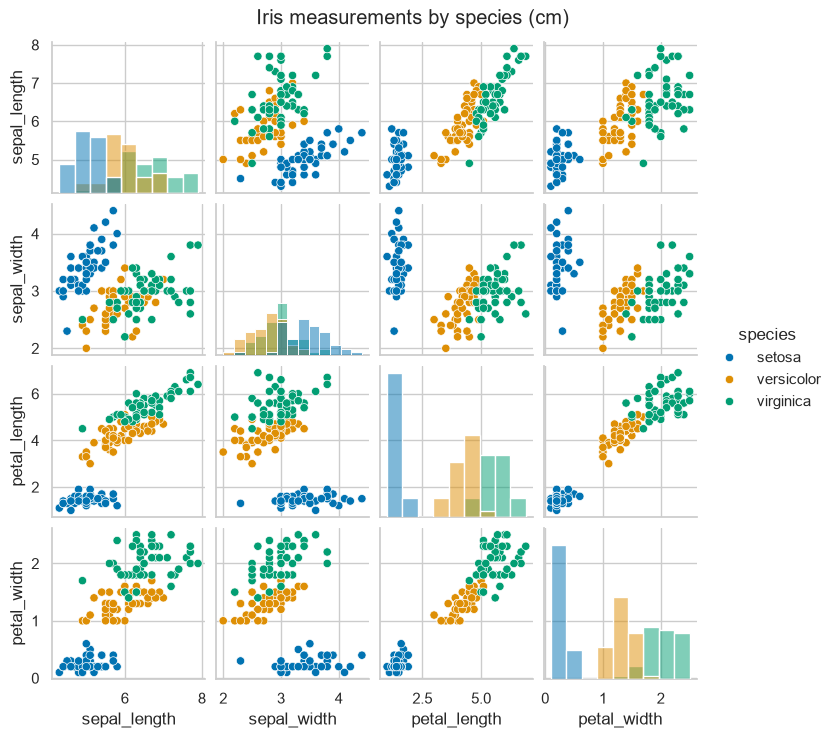

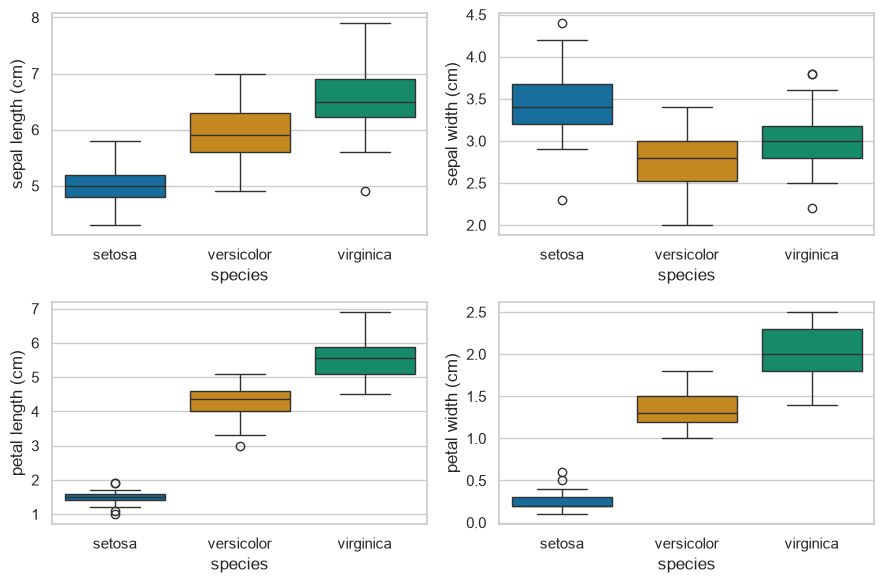

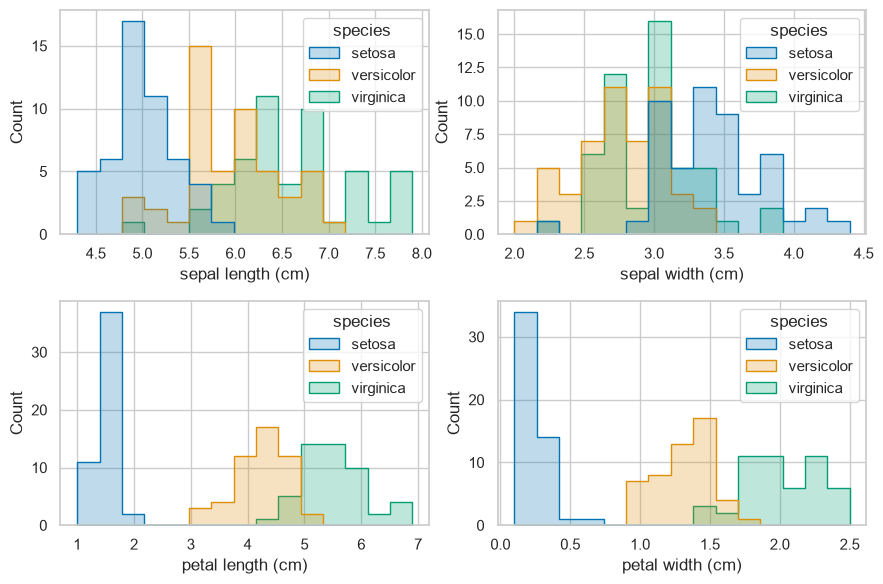

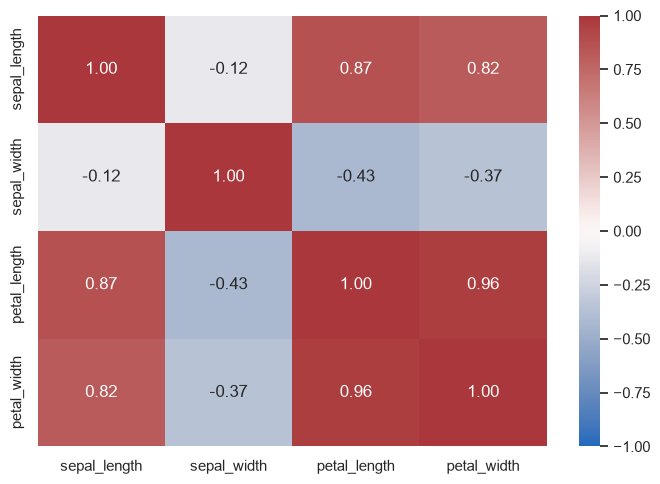

In [2]:
g = sns.pairplot(df, hue="species", diag_kind="hist", height=1.8)
g.fig.suptitle("Iris measurements by species (cm)", y=1.02)
g.savefig(OUT / "pairplot.png", dpi=150, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for col, ax in zip(features, axes.flat):
    sns.boxplot(data=df, x="species", y=col, hue="species", legend=False, ax=ax)
    ax.set_ylabel(col.replace("_", " ") + " (cm)")
fig.tight_layout()
fig.savefig(OUT / "boxplots.png", dpi=150)
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for col, ax in zip(features, axes.flat):
    sns.histplot(data=df, x=col, hue="species", bins=15, element="step", ax=ax)
    ax.set_xlabel(col.replace("_", " ") + " (cm)")
fig.tight_layout()
fig.savefig(OUT / "histograms.png", dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
fig.tight_layout()
fig.savefig(OUT / "correlation.png", dpi=150)
plt.show()

Setosa is easy to pick out in the petal plots. Versicolor and virginica overlap more, especially in the sepal plots. Petal length and petal width tend to increase together.

In [3]:
summary = df[features].agg(["mean", "median", "std", "min", "max"]).T
by_species = df.groupby("species")[features].agg(["mean", "median", "std"])
print(summary.round(3).to_string())
print("\nBy species:\n", by_species.round(3).to_string())
summary.to_csv(OUT / "summary.csv")
by_species.to_csv(OUT / "summary_by_species.csv")

               mean  median    std  min  max
sepal_length  5.843    5.80  0.828  4.3  7.9
sepal_width   3.057    3.00  0.436  2.0  4.4
petal_length  3.758    4.35  1.765  1.0  6.9
petal_width   1.199    1.30  0.762  0.1  2.5

By species:
            sepal_length               sepal_width               petal_length               petal_width              
                   mean median    std        mean median    std         mean median    std        mean median    std
species                                                                                                             
setosa            5.006    5.0  0.352       3.428    3.4  0.379        1.462   1.50  0.174       0.246    0.2  0.105
versicolor        5.936    5.9  0.516       2.770    2.8  0.314        4.260   4.35  0.470       1.326    1.3  0.198
virginica         6.588    6.5  0.636       2.974    3.0  0.322        5.552   5.55  0.552       2.026    2.0  0.275


## Classification
k-NN predicts a flower's species by looking at the most common label among its k nearest training flowers. Scaling is needed because the model uses distances between measurements.

The data are split into 105 training flowers and 45 test flowers, with the same number of each species in both sets. Five-fold cross-validation on the training set compares odd k values from 1 to 25. Scaling is fitted separately within each training fold. If several k values tie, the largest is chosen. The test data are kept aside until this step is complete.

Training rows: 105 Test rows: 45
Selected k: 7 Best training CV accuracy: 0.9619047619047618
Test accuracy: 0.9333333333333333
Confusion matrix (rows=actual, columns=predicted):
 [[15  0  0]
 [ 0 15  0]
 [ 0  3 12]]
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.833     1.000     0.909        15
   virginica      1.000     0.800     0.889        15

    accuracy                          0.933        45
   macro avg      0.944     0.933     0.933        45
weighted avg      0.944     0.933     0.933        45



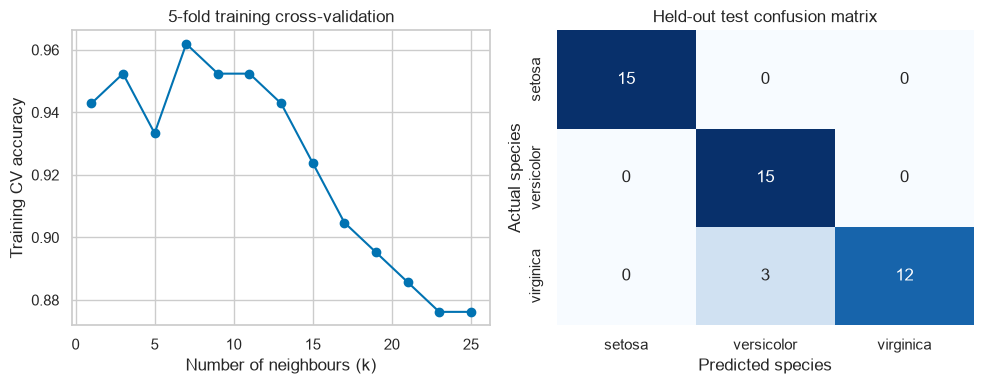

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df[features], df.species, test_size=0.30, random_state=42, stratify=df.species)
pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(pipe, {"knn__n_neighbors": list(range(1, 26, 2))}, cv=cv)
search.fit(X_train, y_train)
scores = search.cv_results_["mean_test_score"]
ks = np.array(search.cv_results_["param_knn__n_neighbors"], dtype=int)
k = int(ks[np.isclose(scores, scores.max(), rtol=0, atol=1e-12)].max())
model = pipe.set_params(knn__n_neighbors=k).fit(X_train, y_train)
pred = model.predict(X_test)
labels = sorted(df.species.unique())
cm = confusion_matrix(y_test, pred, labels=labels)
accuracy = accuracy_score(y_test, pred)
print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Selected k:", k, "Best training CV accuracy:", scores.max())
print("Test accuracy:", accuracy)
print("Confusion matrix (rows=actual, columns=predicted):\n", cm)
print(classification_report(y_test, pred, digits=3))
pd.DataFrame({"k":ks,"mean_cv_accuracy":scores}).to_csv(OUT / "cv_scores.csv",index=False)
pd.DataFrame(cm,index=labels,columns=labels).to_csv(OUT / "confusion_matrix.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks, scores, marker="o")
axes[0].set(xlabel="Number of neighbours (k)", ylabel="Training CV accuracy", title="5-fold training cross-validation")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set(xlabel="Predicted species", ylabel="Actual species", title="Held-out test confusion matrix")
fig.tight_layout()
fig.savefig(OUT / "model.png", dpi=150)
plt.show()
metrics = {"k":k,"accuracy":accuracy,"cv_accuracy":float(scores.max()),"confusion_matrix":cm.tolist(),"labels":labels,"classification_report":classification_report(y_test,pred,output_dict=True)}
(OUT / "metrics.json").write_text(json.dumps(metrics,indent=2))

## Conclusion
The model chose k = 7 and correctly classified 42 of the 45 test flowers, giving 93.3% accuracy. The three errors were virginica flowers labelled as versicolor. All setosa and versicolor test flowers were classified correctly.

The petal plots help explain this result: setosa forms a clear group, while the other two species overlap. The test set is small, so one extra error would change the accuracy by 2.22 percentage points. Trying other models and repeating the evaluation with different splits would give a better idea of how reliable the result is. It would also be useful to check whether the two petal measurements alone give similar results.

Data: Seaborn iris CSV, https://github.com/mwaskom/seaborn-data/blob/master/iris.csv. Packages: pandas, Seaborn, Matplotlib and scikit-learn. The versions used are listed in requirements.txt.